# Phase 3, step 1: item format and prompt builder

* `src/items.py`: the `Item` format, `build_scene` (what the model sees), offside ground truth computed **from the
  displayed scene**, D11 selection, and JSONL save/load.
* `src/prompts.py`: `text_prompt` (coordinates table), `image_prompt` + `render_scene` (image format), in two
  styles (`direct`, `reason`).

This notebook builds the 192 balanced offside items into `items/tier1_offside_v0.jsonl` and shows one item in
both formats.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display
from src.load import list_matches
from src.moments import evaluate_all
from src.items import select_balanced_offside, build_offside_items, save_items, load_items
from src.prompts import text_prompt, image_prompt, render_scene

## 1. Moments → balanced selection (D11)

Reuses Phase 2's cache if present (`tier1_moments.parquet`).

In [2]:
cache = ROOT / "data/processed/qa/tier1_moments.parquet"
moments = pd.read_parquet(cache) if cache.exists() else evaluate_all(list_matches(), workers=4)
if not cache.exists():
    moments.to_parquet(cache, index=False)
selected = select_balanced_offside(moments, seed=2026)
print(f"selected {len(selected)}: {selected.offside.sum()} offside / {(~selected.offside).sum()} onside")
pd.crosstab(selected.margin_bin, selected.offside.map({True: "offside", False: "onside"}))

selected 192: 96 offside / 96 onside


offside,offside,onside
margin_bin,,
"(-0.001, 0.5]",50,50
"(0.5, 1.0]",25,25
"(1.0, 2.0]",20,20
"(2.0, 5.0]",1,1


## 2. Build items

Each item stores the rounded scene (2 decimal places) and recomputes the answer from it. If rounding created an
exact tie or flipped the label, the item is dropped and listed (expected: none).

In [3]:
items, dropped = build_offside_items(selected, orientation="attack_right", decimals=2, include_extrapolated=True)
print(f"items: {len(items)}   dropped: {len(dropped)}")
display(dropped)
path = save_items(items, ROOT / "items" / "tier1_offside_v0.jsonl")
print("saved", path.relative_to(ROOT))
pd.DataFrame([{"source": i.source, "answer": i.answer, **i.difficulty} for i in items]).describe().round(2)

items: 192   dropped: 0


""


saved items/tier1_offside_v0.jsonl


,offside_margin_m,abs_margin_m,receiver_ahead_of_ball_m,pass_distance_m,players_within_10m_of_ball
count,192.00,192.00,192.00,192.00,192.00
mean,-0.04,0.64,9.97,18.50,4.99
std,0.84,0.54,8.01,9.73,2.53
min,-2.06,0.01,0.06,3.89,1.00
25%,-0.49,0.20,4.56,10.85,3.00
50%,0.00,0.49,7.60,17.12,5.00
75%,0.48,0.94,13.11,24.33,7.00
max,2.16,2.16,47.89,52.62,15.00


## 3. One item in both formats

The clearest SkillCorner offside (largest margin), as the model would see it.

In [4]:
it = max((i for i in items if i.answer == "A" and i.source == "skillcorner"), key=lambda i: i.difficulty["abs_margin_m"])
print(it.item_id, it.match_id, it.frame_id, "answer:", it.answer, it.difficulty)
print()
print(text_prompt(it, style="direct"))

t1-offside-6dd3c16abc 2015213 21726 answer: A {'offside_margin_m': 2.16, 'abs_margin_m': 2.16, 'receiver_ahead_of_ball_m': 20.79, 'pass_distance_m': 21.07, 'players_within_10m_of_ball': 5}

You are given a snapshot of a football (soccer) match from tracking data.

Pitch: 106 m long (x axis) by 68 m wide (y axis). Origin (0, 0) is the centre spot; x runs from -53 to +53 and y from -34 to +34. Units are metres.
Blue is in possession and attacks towards +x: Blue is trying to score in the goal at x = +53. Orange defends that goal.

Rule: Offside position (Laws of the Game, Law 11): a player is in an offside position if any part of the head, body or feet is in the opponents' half (excluding the halfway line) and is nearer to the opponents' goal line than both the ball and the second-last opponent. Being level with the second-last opponent or the ball is NOT an offside position. Treat each player as the single point given.

Positions at this moment (each player is a single point):
player | x

The image shows a snapshot of a football (soccer) match from tracking data, viewed from above. The pitch is 106 m by 68 m. Blue dots are Blue players and orange dots are Orange players, each labelled with a shirt number; the small black dot is the ball. Blue is in possession and attacks towards the right (arrow above the pitch).

Rule: Offside position (Laws of the Game, Law 11): a player is in an offside position if any part of the head, body or feet is in the opponents' half (excluding the halfway line) and is nearer to the opponents' goal line than both the ball and the second-last opponent. Being level with the second-last opponent or the ball is NOT an offside position. Treat each player as the single point given.

Question: Blue 32 is about to pass the ball to Blue 4. At this moment, is Blue 4 in an offside position?
A) Yes, offside position
B) No, not in an offside position

Reason step by step. Then, on the final line, output only this JSON:
{"answer": "<A|B>", "confidence": <i

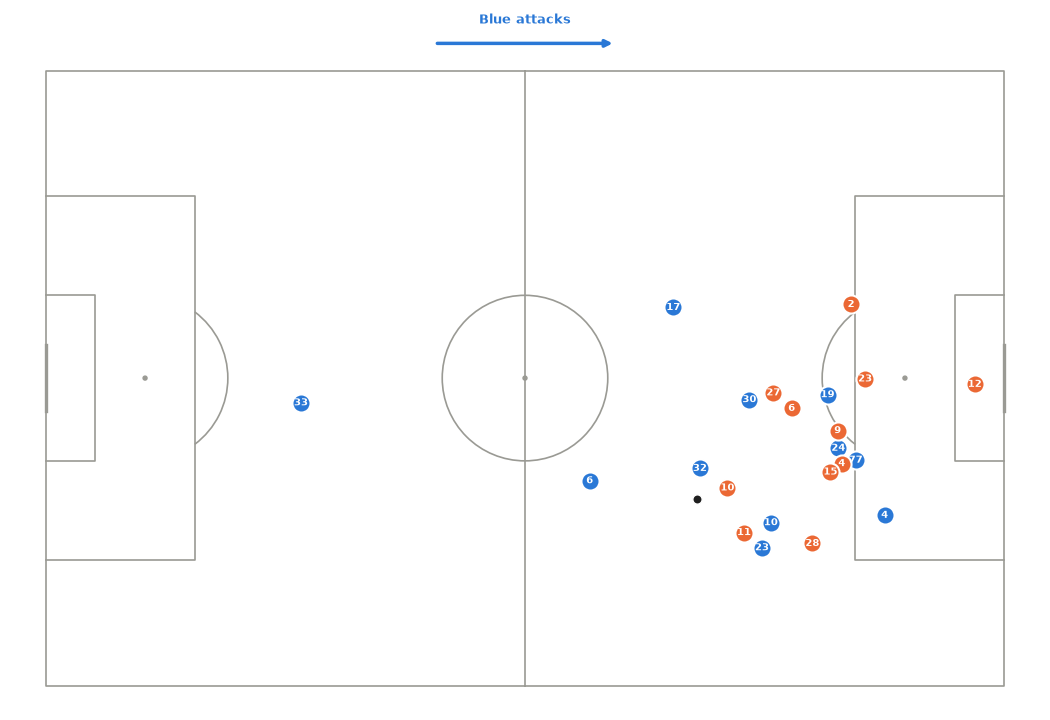

In [5]:
print(image_prompt(it, style="reason"))
render_scene(it, ROOT / "notebooks" / "figures" / "example_item_image.png")
display(Image(filename=str(ROOT / "notebooks" / "figures" / "example_item_image.png")))

## 4. Sanity check: reload and verify answers from the file

Every stored answer must be recomputable from the stored scene alone.

In [6]:
from src.items import offside_truth
back = load_items(ROOT / "items" / "tier1_offside_v0.jsonl")
ok = all(offside_truth(i.scene, i.provenance["receiver"])["offside"] == i.answer_value for i in back)
print(len(back), "items reloaded; all answers recomputable from the scene:", ok)

192 items reloaded; all answers recomputable from the scene: True
